# Домашняя работа № 1
## Анализ данных для распознавания спама в SMS

### 1. Постановка задачи

**Бизнес-задача:** разработать фильтр, который определяет спам
в SMS-сообщениях. Такой фильтр должен уменьшать количество
нежелательных сообщений и сохранять доступ к обычной переписке.

**Задача машинного обучения:** бинарная классификация текстов.
По тексту сообщения необходимо определить его класс:
ham - обычное сообщение, spam - спам.

**Набор данных:** SMS Spam Collection из репозитория UCI.
Каждый объект содержит текст SMS и метку класса.
Наличие размеченных сообщений позволяет использовать набор
для обучения и оценки классификатора.

Брал отсюда: https://archive.ics.uci.edu/dataset/228/sms+spam+collection

In [ ]:
import io
import zipfile
import urllib.request

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#тут загружаю архивчик с исходными данными
url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

with urllib.request.urlopen(url) as response:
    archive_bytes = response.read()

#читаю сообщения и метки классов из архива
with zipfile.ZipFile(io.BytesIO(archive_bytes)) as archive:
    with archive.open("SMSSpamCollection") as file:
        df = pd.read_csv(
            file,
            sep="\t",
            header=None,
            names=["label", "message"],
            quoting=3
        )

display(df.head())
print(f"Количество строк: {df.shape[0]}")
print(f"Количество столбцов: {df.shape[1]}")

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


Количество строк: 5574
Количество столбцов: 2


### 2. Выбор метрик качества

Основная метрика — F1 для класса spam. Она учитывает одновременно
precision и recall, то есть помогает оценить и ошибочную фильтрацию
обычных сообщений, и пропуск спама.

Дополнительно буду оценивать precision для класса spam:
важно, чтобы обычная переписка редко попадала в спам.
Метрики будут рассчитаны после обучения модели в следующих работах.

### 3. Разведочный анализ данных
#### 3.1. Проверка структуры и качества данных

Проверю типы данных, пропуски, пустые сообщения, повторяющиеся
строки и распределение классов.

In [ ]:
#проверяю структуру таблицы
df.info()

#и пропуски
print("\nПропуски:")
print(df.isna().sum())

#и сообщения без текста
empty_messages = df["message"].fillna("").str.strip().eq("")
print("\nПустые сообщения:", empty_messages.sum())

#считаю полные дубликаты строк
print("\nПолные дубликаты:", df.duplicated().sum())

#проверяю количество и долю сообщений каждого класса
class_stats = df["label"].value_counts(dropna=False).to_frame("Количество")
class_stats["Доля, %"] = (
    class_stats["Количество"] / len(df) * 100
).round(2)

display(class_stats)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5574 entries, 0 to 5573
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5574 non-null   object
 1   message  5574 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB

Пропуски:
label      0
message    0
dtype: int64

Пустые сообщения: 0

Полные дубликаты: 403


,Количество,"Доля, %"
label,,
ham,4827,86.6
spam,747,13.4


В наборе 5574 сообщения. Пропуски и пустые тексты отсутствуют.
Обнаружено 403 полных дубликата. Удалю их, чтобы одинаковые
сообщения не искажали анализ и в дальнейшем не попали
одновременно в обучающую и тестовую выборки.

Классы несбалансированы: обычные сообщения составляют 86,6%,
спам — 13,4%. Если всегда предсказывать обычное сообщение,
accuracy составит 86,6%, хотя ни одно спам-сообщение
не будет обнаружено. Поэтому одной accuracy недостаточно.

Количество сообщений после удаления дубликатов: 5171
Тексты с разными метками: 0


,count
label,
ham,4518
spam,653


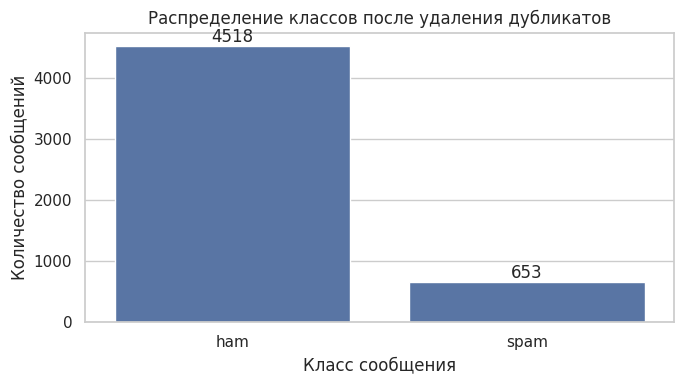

In [ ]:
#тут я удаляю полные дубликаты и обновляю индекс
df = df.drop_duplicates().reset_index(drop=True)

print("Количество сообщений после удаления дубликатов:", len(df))

#тут проверяю есть ли одинаковые тексты с разными метками
conflicting_labels = df.groupby("message")["label"].nunique()
print("Тексты с разными метками:", (conflicting_labels > 1).sum())

#а тут показываю распределение классов после удаления дубликатов
display(df["label"].value_counts())

#аааа тууут у меня график количества сообщений каждого класса
sns.set_theme(style="whitegrid")

plt.figure(figsize=(7, 4))
ax = sns.countplot(data=df, x="label", order=["ham", "spam"])

ax.bar_label(ax.containers[0])
plt.title("Распределение классов после удаления дубликатов")
plt.xlabel("Класс сообщения")
plt.ylabel("Количество сообщений")
plt.tight_layout()
plt.show()

После удаления дубликатов осталось 5171 сообщение.
Противоречивые метки у одинаковых текстов не обнаружены.
На графике видно, что дисбаланс классов сохранился.

#### 3.2. Анализ длины сообщений

Сравню количество символов и слов в обычных сообщениях и спаме.
Проверю, могут ли эти характеристики помочь при классификации.

char_count                                                  word_count  \
           count    mean    std   min    25%    50%    75%    max      count   
label                                                                          
ham       4518.0   70.89  56.59   2.0   34.0   53.0   91.0  910.0     4518.0   
spam       653.0  137.71  29.82  13.0  132.0  148.0  157.0  223.0      653.0   

                                                   
        mean    std  min   25%   50%   75%    max  
label                                              
ham    14.23  11.16  1.0   7.0  11.0  19.0  171.0  
spam   23.74   5.93  2.0  22.0  25.0  28.0   35.0

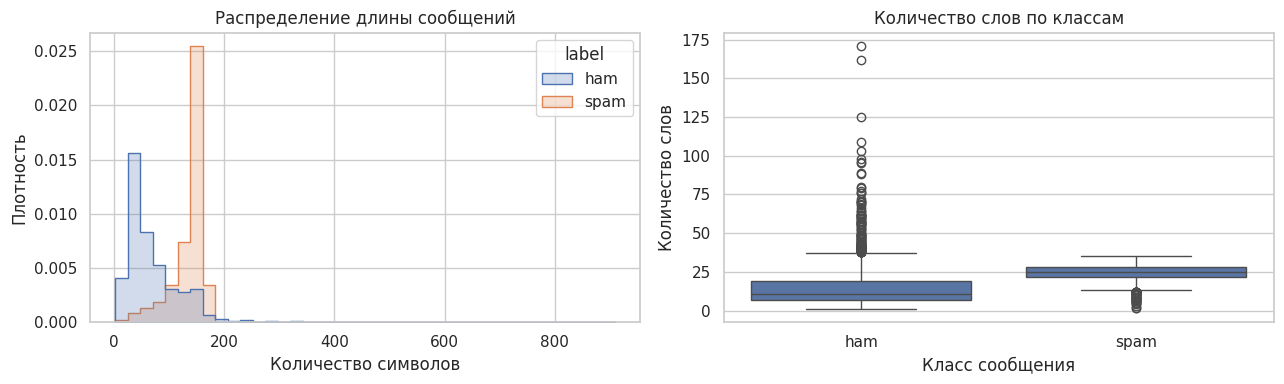

In [ ]:
#считаю символы, тут у нас и пробелы и знаки препинания
df["char_count"] = df["message"].str.len()

#люблю считать поэтому считаю слова по разделению текста пробельными символами
df["word_count"] = df["message"].str.split().str.len()

#не люблю сравнивать но сравниваю основные статистики по классам
display(
    df.groupby("label")[["char_count", "word_count"]]
    .describe()
    .round(2)
)

#и сравниваю распределения длины сообщений
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(
    data=df,
    x="char_count",
    hue="label",
    hue_order=["ham", "spam"],
    bins=40,
    stat="density",
    common_norm=False,
    element="step",
    ax=axes[0]
)
axes[0].set_title("Распределение длины сообщений")
axes[0].set_xlabel("Количество символов")
axes[0].set_ylabel("Плотность")

sns.boxplot(
    data=df,
    x="label",
    y="word_count",
    order=["ham", "spam"],
    ax=axes[1]
)
axes[1].set_title("Количество слов по классам")
axes[1].set_xlabel("Класс сообщения")
axes[1].set_ylabel("Количество слов")

plt.tight_layout()
plt.show()

Средняя длина обычного сообщения — 70,89 символа,
спама — 137,71. Медианное количество слов составляет
11 для обычных сообщений и 25 для спама.

Распределения пересекаются, поэтому одной длины недостаточно
для надёжной классификации. При этом длину можно использовать
как дополнительный признак.

Среди обычных сообщений встречаются длинные тексты:
максимум — 910 символов. Точки за пределами усов на boxplot
не обязательно являются ошибками, поэтому автоматически
удалять такие сообщения не буду.

#### 3.3. Дополнительные признаки сообщений

Проверю, как часто в каждом классе встречаются цифры,
восклицательные знаки и ссылки с http, https или www.

,Есть цифры,Есть знак !,Есть ссылка
label,,,
ham,15.83,11.73,0.02
spam,94.03,47.32,13.78


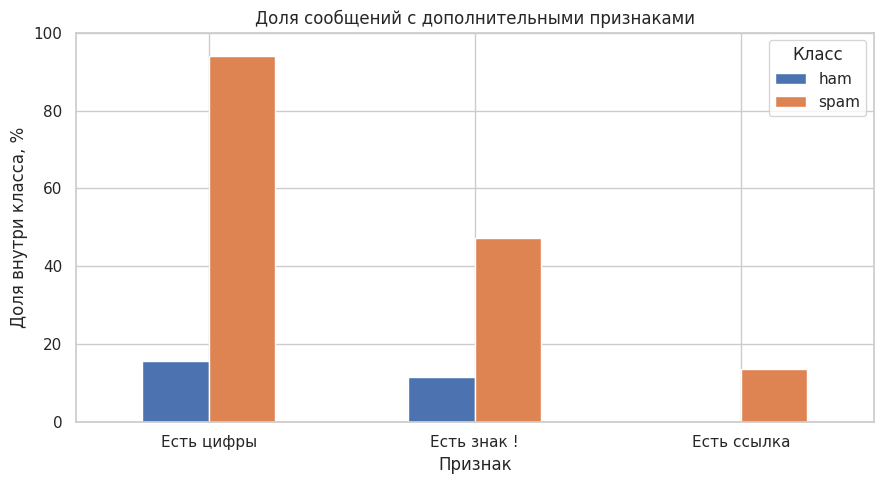

In [ ]:
#опять проверяю наличие цифр, восклицательных знаков и ссылок(
df["has_digit"] = df["message"].str.contains(r"\d", regex=True)
df["has_exclamation"] = df["message"].str.contains("!", regex=False)
df["has_link"] = df["message"].str.contains(
    r"https?://|www\.",
    case=False,
    regex=True
)

#считаю долю сообщений с каждым признаком
feature_share = (
    df.groupby("label")[
        ["has_digit", "has_exclamation", "has_link"]
    ].mean() * 100
)

feature_share = feature_share.rename(columns={
    "has_digit": "Есть цифры",
    "has_exclamation": "Есть знак !",
    "has_link": "Есть ссылка"
})

display(feature_share.round(2))

#с р а в н и в а ю доли, чтобы учесть разное количество сообщений в классах
ax = feature_share.T.plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

ax.set_title("Доля сообщений с дополнительными признаками")
ax.set_xlabel("Признак")
ax.set_ylabel("Доля внутри класса, %")
ax.set_ylim(0, 100)
ax.legend(title="Класс")

plt.tight_layout()
plt.show()

Цифры встречаются в 94,03% спам-сообщений и в 15,83% обычных.
Восклицательные знаки — в 47,32% спама и в 11,73% обычных сообщений.

Ссылки с http, https или www обнаружены в 13,78% спама
и в 0,02% обычных сообщений. Использованный способ поиска
не учитывает адреса без этих префиксов.

Эти признаки могут помочь классификатору. Однако наличие
цифры, ссылки или восклицательного знака само по себе
не означает, что сообщение является спамом.

### 4. Выводы и дальнейшая обработка

Я сформулировал задачу бинарной классификации SMS
и выбрал F1 для класса spam как основную метрику.
Дополнительно буду контролировать precision, чтобы оценивать
ошибочное отнесение обычных сообщений к спаму.

В ходе анализа я проверил структуру данных, пропуски,
дубликаты и распределение классов. После удаления 403
дубликатов осталось 5171 сообщение: 4518 обычных и 653 спам.
Пропуски, пустые сообщения и противоречивые метки не обнаружены.

В этом наборе спам в среднем длиннее обычных сообщений.
В нём чаще встречаются цифры, восклицательные знаки и ссылки.
Эти различия дают основания проверить дополнительные
признаки при обучении модели, но пока не доказывают
качество будущего классификатора.

При дальнейшей работе планирую:

1. Разделить данные на обучающую и тестовую выборки
   с сохранением долей классов.
2. Преобразовать тексты в числовые признаки методом TF-IDF.
   Словарь и веса обучать только на обучающей выборке.
3. Проверить пользу длины сообщений и дополнительных признаков.
4. Оценить F1, precision и recall для класса spam.
5. Отдельно разобрать пропущенный спам и обычные сообщения,
   ошибочно отнесённые к спаму.